In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [2]:
words = open('names.txt').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [3]:
# build vocabulary and mapping from characters to integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i , s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [5]:
# build dataset
# trigram dataset
block_size = 3
def build_dataset(words):
    X, y = [], []
    for word in words:
        context = [0] * block_size
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    y = torch.tensor(y)
    return X, y
     

In [6]:
# create test train dev splits
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
X_tr, y_tr = build_dataset(words=words[:n1])
X_dev, y_dev = build_dataset(words=words[n1:n2])
X_te, y_te = build_dataset(words=words[n2:])

In [11]:
# MLP
d_emb = 10
vocab_size = len(chars) + 1
n_hidden = 200
g = torch.Generator().manual_seed(550)

C = torch.randn((vocab_size , d_emb), generator=g)
W1 = torch.randn(block_size * d_emb, n_hidden, generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn(n_hidden, vocab_size)
b2 = torch.randn(vocab_size)

parameters = [C, W1, b1, W2, b2]
num_params = 0
for p in parameters:
    p.requires_grad = True
    num_params  += p.numel()
num_params

11897

In [12]:
# optimization
max_steps = 100000
batch_size = 32
lossi = []
for i in range(max_steps):
    
    # create a minibatch
    ix = torch.randint(0, X_tr.shape[0], (batch_size,), generator=g)
    Xb = X_tr[ix]
    yb = y_tr[ix]

    # forward pass
    embs = C[Xb] # it will have shape of (shapeof Xb, 10) shape of Xb = 32, 3 so 32, 3, 10
    # but we need shape 32, 30, concatenated vectors so 
    embcat = embs.view(embs.shape[0], -1) # concatenated vectors

    h1 =  torch.tanh(embcat @ W1 + b1) # hidden layer outputs w  tanh activation
    logits = h1 @ W2 + b2 # output logits

    loss = F.cross_entropy(logits, yb) # loss

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step
    lr = 0.1 if i < 70000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad
    
    if i % 1000 == 0:
        print(f'{i:7d}/ {max_steps:7d} {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/  100000 33.1111
   1000/  100000 4.2313
   2000/  100000 2.5331
   3000/  100000 3.6793
   4000/  100000 3.3758
   5000/  100000 2.7567
   6000/  100000 2.9845
   7000/  100000 2.6280
   8000/  100000 2.0358
   9000/  100000 2.6628
  10000/  100000 2.7446
  11000/  100000 2.2639
  12000/  100000 2.3107
  13000/  100000 2.3264
  14000/  100000 2.1435
  15000/  100000 2.1187
  16000/  100000 2.4268
  17000/  100000 2.1715
  18000/  100000 2.5499
  19000/  100000 2.2374
  20000/  100000 2.3844
  21000/  100000 2.4148
  22000/  100000 2.1872
  23000/  100000 1.9865
  24000/  100000 2.3534
  25000/  100000 2.0950
  26000/  100000 2.6517
  27000/  100000 2.4518
  28000/  100000 2.2406
  29000/  100000 2.3873
  30000/  100000 2.3165
  31000/  100000 2.5598
  32000/  100000 2.4753
  33000/  100000 2.4659
  34000/  100000 2.5174
  35000/  100000 2.7461
  36000/  100000 2.0764
  37000/  100000 2.1139
  38000/  100000 2.9966
  39000/  100000 2.5961
  40000/  100000 2.3505
  41000/  10000

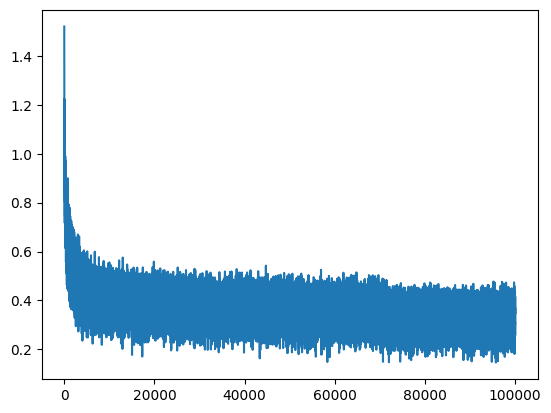

In [13]:
plt.plot(lossi)

In [14]:
# test loss and val loss
@torch.no_grad()
def split_loss(split):
    x, y = {"train": (X_tr, y_tr), "val": (X_dev, y_dev), "test": (X_te, y_te)}[split]
    embs = C[x]
    embcat = embs.view(embs.shape[0], -1)
    h1 =torch.tanh(embcat @ W1 + b1)
    logits = h1 @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())
split_loss('train')
split_loss('val')

train 2.13899302482605
val 2.1688733100891113


In [25]:
# sample from model
for _ in range(12):
    
    out  = []
    context = [0] * block_size
    while True:
        embs = C[torch.tensor(context)]
        embcat = embs.view(1, -1)
        h1 =torch.tanh(embcat @ W1 + b1)
        logits = h1 @ W2 + b2
        probs = F.softmax(logits, dim=1)

        ix = torch.multinomial(probs, 1, replacement=True).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print("".join(itos[i] for i in out))


smee.
bryluah.
suz.
gavina.
brafe.
solen.
gric.
babet.
aldiraedaly.
mille.
alamaly.
brank.


# Model weight initialization
Depending on the problem type and type of loss function used, we can have an initial estimate the initial loss. and random initialization will most likely record higher loss than the expected so we can change the method of initialization to get a lower loss at the start.
For example for a classification task, without any training we have no reason to classify any class with higher probability than other, unless we do have a specific reason, so we'd be saving compute by initializing so that the output logits of the nn are close to zero, that corresponds to softmax probabilities of equal to each class. By saving compute we reduce the unnecessary training time to get the probabilities uniform and then optimizing to correct values. 
As we can see in the above training loss log, the starting loss is 27, which after 1000 iterations comes down to 4. Actually even if we started with assumption that each trigram is equally likely given any sequence of trigram, ie, the NLL should be $-ln(1/27) = 3.29$ which we take about 1000 iterations to get to. The point is that we can save training time by smart initialization of weights.

One way to do is to scale down the weights at initialization so that they are close to zero, and hence they produce all the logits close to zero producing a uniform probability distribution. Also we can keep the biases at zero during initialization.

In [26]:

# So if we  do )
# MLP
d_emb = 10
vocab_size = len(chars) + 1
n_hidden = 200
g = torch.Generator().manual_seed(550)

C = torch.randn((vocab_size , d_emb), generator=g)
W1 = torch.randn(block_size * d_emb, n_hidden, generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn(n_hidden, vocab_size) * 0.1
b2 = torch.randn(vocab_size) * 0

parameters = [C, W1, b1, W2, b2]
num_params = 0
for p in parameters:
    p.requires_grad = True
    num_params  += p.numel()
num_params

11897

In [27]:
# optimization
max_steps = 100000
batch_size = 32
lossi = []
for i in range(max_steps):
    
    # create a minibatch
    ix = torch.randint(0, X_tr.shape[0], (batch_size,), generator=g)
    Xb = X_tr[ix]
    yb = y_tr[ix]

    # forward pass
    embs = C[Xb] # it will have shape of (shapeof Xb, 10) shape of Xb = 32, 3 so 32, 3, 10
    # but we need shape 32, 30, concatenated vectors so 
    embcat = embs.view(embs.shape[0], -1) # concatenated vectors

    h1 =  torch.tanh(embcat @ W1 + b1) # hidden layer outputs w  tanh activation
    logits = h1 @ W2 + b2 # output logits

    loss = F.cross_entropy(logits, yb) # loss

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step
    lr = 0.1 if i < 70000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad
    
    if i % 1000 == 0:
        print(f'{i:7d}/ {max_steps:7d} {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/  100000 3.9020
   1000/  100000 2.2931
   2000/  100000 1.7084
   3000/  100000 2.6639
   4000/  100000 2.7314
   5000/  100000 2.2883
   6000/  100000 2.6213
   7000/  100000 2.2810
   8000/  100000 1.9498
   9000/  100000 2.4494
  10000/  100000 2.3579
  11000/  100000 2.0744
  12000/  100000 2.2897
  13000/  100000 2.1500
  14000/  100000 2.1174
  15000/  100000 1.9968
  16000/  100000 2.1408
  17000/  100000 2.1416
  18000/  100000 2.3489
  19000/  100000 2.1909
  20000/  100000 2.3789
  21000/  100000 2.4726
  22000/  100000 2.2351
  23000/  100000 1.8984
  24000/  100000 2.2177
  25000/  100000 2.0118
  26000/  100000 2.4806
  27000/  100000 2.1154
  28000/  100000 2.0178
  29000/  100000 2.0506
  30000/  100000 2.2097
  31000/  100000 2.0904
  32000/  100000 2.1918
  33000/  100000 2.2099
  34000/  100000 2.2452
  35000/  100000 2.3499
  36000/  100000 1.9518
  37000/  100000 2.1969
  38000/  100000 2.6930
  39000/  100000 2.3366
  40000/  100000 2.2277
  41000/  100000

In [28]:
split_loss('train')
split_loss('val')

train 2.0868570804595947
val 2.1405763626098633


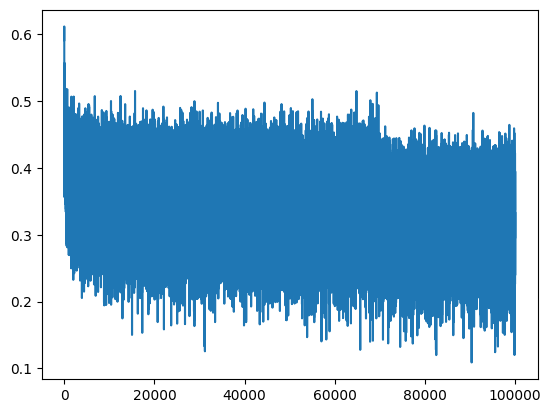

In [29]:
plt.plot(lossi) 

The above loss results show that for same iterations we have got a lower loss, since we used that time to do productive optimization. We reduced the training loss from 2.13 --> 2.08 and val loss from 2.16 --> 2.14. And from the loss plot we see that we also got rid of the 'hockey stick' loss output.
### Next issue.
Theere is another issue in the hidden layer neurons


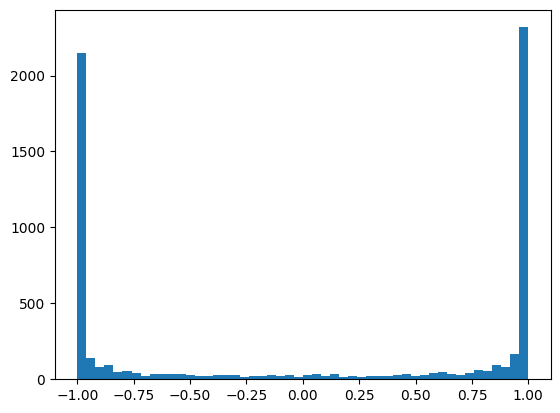

In [30]:
plt.hist(h1.view(-1).tolist(), bins=50);

### Kaiming/He initialization
In the histogram we see that a lot of the activation outputs are at the values 1 and -1, This means that the preactivation values are spread out very far from zero hence they lie on the flat regions of tanh. And at the flat regions we have zero gradients. This is the **vanishing gradients** problem.   
If it happens to be a case so that if a neuron is on the flat region for every training example, then that neuron can't learn and is essentially a dead neuron.   
We can fix these issues by making sure that the inputs of tanh are close to zero, which can be acheived by initializing the weights and biases of previous layers close to zero.   
But how close? How is the factor that is multiplied by the randomly initialized weights calculated? For this we have Kaiming/He initialization https://docs.pytorch.org/docs/stable/nn.init.html
In the earlier days precise settings of the intial weights was crucial but it has become more less important with some innovations today. That includes  

### Batch normalization
When this was introduced, it allowed us to training very deep neural nets reliably. This was based on the very simple idea that if it is good for the hidden state activations to be close to the standard normal distribution, just take them and normalize them to be gaussian. This is allowable because normalizing to gausian is a differentiable operation and hence we can do gradient descent.  
![](../images/bn.png "Batch normalization algorithm")  
The problem is we don't want them to be unit gaussian not every time but just at the initialization and then later gradient descent decide that shape later as training goes on. So we multiply by a batch gain and add a batch bias which are the learnable parameters for the batch norm layer.



In [46]:
# with batch  normalization
# MLP
d_emb = 10
vocab_size = len(chars) + 1
n_hidden = 200
g = torch.Generator().manual_seed(550)

C = torch.randn((vocab_size , d_emb), generator=g)
# kaiming/he initialization
W1 = torch.randn(block_size * d_emb, n_hidden, generator=g) * (5/3) / ((block_size * d_emb) ** 0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn(n_hidden, vocab_size, generator=g) * 0.1
b2 = torch.randn(vocab_size, generator=g) * 0.01

bn_gain = torch.ones((1, n_hidden))
bn_bias = torch.zeros((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bn_gain, bn_bias]
num_params = 0
for p in parameters:
    p.requires_grad = True
    num_params  += p.numel()
num_params

12297

In [47]:
# optimization
# with batch normalizatoin
max_steps = 100000
batch_size = 32
lossi = []
for i in range(max_steps):
    
    # create a minibatch
    ix = torch.randint(0, X_tr.shape[0], (batch_size,), generator=g)
    Xb = X_tr[ix]
    yb = y_tr[ix]

    # forward pass
    embs = C[Xb] # it will have shape of (shapeof Xb, 10) shape of Xb = 32, 3 so 32, 3, 10
    # but we need shape 32, 30, concatenated vectors so 
    embcat = embs.view(embs.shape[0], -1) # concatenated vectors

    h_preact  = embcat @ W1 + b1
    h_preact = bn_gain * (h_preact - h_preact.mean(0, keepdim=True)) / h_preact.std(dim=0) + bn_bias
    h1 =  torch.tanh(h_preact) # hidden layer outputs w  tanh activation
    logits = h1 @ W2 + b2 # output logits

    loss = F.cross_entropy(logits, yb) # loss

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # step
    lr = 0.1 if i < 70000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad
    
    if i % 10000 == 0:
        print(f'{i:7d}/ {max_steps:7d} {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/  100000 3.5081
  10000/  100000 2.2187
  20000/  100000 2.3269
  30000/  100000 2.4411
  40000/  100000 2.6160
  50000/  100000 2.2174
  60000/  100000 2.3153
  70000/  100000 2.0933
  80000/  100000 2.2863
  90000/  100000 1.8539


In [48]:
# test loss and val loss
@torch.no_grad()
def split_loss(split):
    x, y = {"train": (X_tr, y_tr), "val": (X_dev, y_dev), "test": (X_te, y_te)}[split]
    embs = C[x]
    embcat = embs.view(embs.shape[0], -1)
    h_preact  = embcat @ W1 + b1
    h_preact = bn_gain * (h_preact - h_preact.mean(0, keepdim=True)) / h_preact.std(dim=0) + bn_bias
    h1 =  torch.tanh(h_preact) # hidden layer outputs w  tanh activation
    logits = h1 @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())
split_loss('train')
split_loss('val')

train 2.090261697769165
val 2.1221489906311035


In [ ]:
# loss with just batch normalization
# train 2.216073513031006
# val 2.2206881046295166

# loss with batch normalization and kaiming/he initialization on just W1
# train 2.159510374069214
# val 2.171653985977173

# loss with batch normalization and kaiming/he initialization on W1 and W2
# train 2.090261697769165
# val 2.1221489906311035

### Bad part about batch normalization. 
Although adding batch norm layers throughout the neural net normalizes the activations throughout the network and helps in training. this comes at cost. It is that that the examples that happened to be selected for a minibatch are coupled mathematically through the mean and variance of the batch as opposed to independent logit calculation without it. So the hidden state activations and the logits for an example are not just the function of itself, but also the other examples that happended to be selected in the batch, so for a same example there will be some randomness, in the activations and logits for that example. This actually happens to have a positive regularizer like effect in a sense that it makes it harder for neural net to overfit to those examples. But this property also leads to different strange bugs. So other normalization methods, (instance normalization, group normalization, layer normalization) that don't couple the examples in the batch are used in attempt to deprecate the use of batch norm.   
Other thing is that since we compute mean and std in forward pass for a batch, the network now expects the inputs to be in batches, but at inference time we'd like to be able to compute probabilities for a single example. To solve this, after training the net, we can calibrate the mean and standard deviations to fixed values using the entire training dataset. But that is an extra step after training and no one likes to do it. So what we do is keep a running mean and standard deviation and keep updating with a sort of running mean manner aside from training.  
Other point is that we don't need biases on the linear layers before the batch norm layers since we are just averaging out and adding another bias from the batch norm layer anyway. 

In [ ]:
#